# 05 Modelling

This notebook corresponds to the **Machine Learning Modelling** stage.

Goals:
- Predict station imbalance 30 minutes ahead for Dublin Bikes

In [ ]:
import torch
import time


print("torch:", torch.__version__)
print("cuda runtime:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("archs:", torch.cuda.get_arch_list())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

x = torch.rand(3000, 3000, device=device)
y = torch.rand(3000, 3000, device=device)

torch.cuda.synchronize()
t0 = time.time()
z = x @ y
torch.cuda.synchronize()
t1 = time.time()

print("Result device:", z.device)
print("Elapsed:", t1 - t0, "seconds")

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED) 
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

torch: 2.10.0+cu128
cuda runtime: 12.8
cuda available: True
archs: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
gpu: NVIDIA GeForce RTX 5060 Laptop GPU
Using: cuda
Result device: cuda:0
Elapsed: 0.26764917373657227 seconds



## 1. Load engineered dataset with trend

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path('..').resolve()
FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.parquet'
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features_v2.csv.gz'

if FEATURES_PATH.suffix == '.parquet':
    df = pd.read_parquet(FEATURES_PATH).copy()
else:
    df = pd.read_csv(FEATURES_PATH).copy()

df = df.sort_values(['station_id', 'last_reported'])
print(df.shape)
df.head()

(13513883, 19)


,station_id,last_reported,hour_slot,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,empty_risk,full_risk,center_index,area_type_str,util_prev,time_prev,delta_util,delta_min,util_slope,util_vs_mean
0,1,2022-04-27 13:00:02,13,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail,NaN,NaT,NaN,NaN,NaN,0.0
1,1,2022-04-27 13:30:02,13,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail,0.0,2022-04-27 13:00:02,0.0,30.0,0.0,0.0
2,1,2022-04-27 14:00:02,14,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail,0.0,2022-04-27 13:30:02,0.0,30.0,0.0,0.0
3,1,2022-04-27 14:30:02,14,2,True,0.0,0.0,0.0,0.000000,True,False,1,retail,0.0,2022-04-27 14:00:02,0.0,30.0,0.0,0.0
4,1,2022-04-27 15:00:02,15,2,True,0.0,0.0,0.0,0.000000,True,False,1,retail,0.0,2022-04-27 14:30:02,0.0,30.0,0.0,0.0


## 2. Create targets

In [ ]:
# target variable: utilisation 30 min in the future

df = df.sort_values(["station_id", "last_reported"]).copy()

def get_target(group):
    group = group.sort_values("last_reported").copy()

    # preserve station_id explicitly
    sid = group["station_id"].iloc[0]

    times = group["last_reported"].to_numpy()
    values = group["utilisation"].to_numpy()

    target = np.full(len(group), np.nan)

    for i in range(len(times)):
        t_future = times[i] + np.timedelta64(30, "m")
        idx = np.searchsorted(times, t_future, side="left")
        if idx < len(times):
            target[i] = values[idx]

    group["utilisation_tplus_30"] = target
    group["station_id"] = sid
    return group

parts = []
for _, g in df.groupby("station_id", sort=False):
    parts.append(get_target(g))

df = pd.concat(parts, ignore_index=True)


## Targets
# 1- Multiclass: Define bands for 30‑min ahead utilisation 
def utilisation_band(u):
    if u < 0.05:
        return 0   # empty
    elif u < 0.30:
        return 1   # low
    elif u < 0.70:
        return 2   # balanced
    elif u < 0.95:
        return 3   # high
    else:
        return 4   # full

df["band_30min"] = df["utilisation_tplus_30"].apply(utilisation_band)
# band_labels = sorted(df["band_30min"].unique())
band_labels = [0, 1, 2, 3, 4]
print("Band distribution:\n", df["band_30min"].value_counts(normalize=True).sort_index())


# 2- Binary targets:
df["empty_in_30min"] = df["utilisation_tplus_30"] < 0.05
df["full_in_30min"]  = df["utilisation_tplus_30"] > 0.95



  

Band distribution:
 band_30min
0    0.150778
1    0.308408
2    0.360161
3    0.129838
4    0.050816
Name: proportion, dtype: float64


In [ ]:
# df.info()

print(df.columns)
print(df.index.names)

Index(['station_id', 'last_reported', 'hour_slot', 'days_of_week',
       'is_weekday', 'roll_mean_30min', 'roll_std_30min', 'utilisation',
       'dock_ratio', 'empty_risk', 'full_risk', 'center_index',
       'area_type_str', 'util_prev', 'time_prev', 'delta_util', 'delta_min',
       'util_slope', 'util_vs_mean', 'utilisation_tplus_30', 'band_30min',
       'empty_in_30min', 'full_in_30min'],
      dtype='str')
[None]


## 3. Drop missing rows rows

In [ ]:
# Count na per station
na_per_station = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .apply(lambda x: x.isna().sum())
      .reset_index(name="na_count")
)

# Add total rows per station
counts = (
    df.groupby("station_id")["utilisation_tplus_30"]
      .size()
      .reset_index(name="total_rows")
)

na_stats = na_per_station.merge(counts, on="station_id")

# Percentage of na 
na_stats["na_ratio"] = na_stats["na_count"] / na_stats["total_rows"]

# worst stations with most na in target
na_stats.sort_values("na_ratio", ascending=False).head(10)
problematic = na_stats[na_stats["na_ratio"] > 0.5]
print(problematic)

# summary of na_ratio across stations
print(na_stats["na_ratio"].describe())


# Drop rows with na in target
df = df.dropna(subset=["utilisation_tplus_30", "util_slope", "util_vs_mean"])

Empty DataFrame
Columns: [station_id, na_count, total_rows, na_ratio]
Index: []
count    115.000000
mean       0.000033
std        0.000010
min        0.000022
25%        0.000027
50%        0.000033
75%        0.000035
max        0.000126
Name: na_ratio, dtype: float64


## 4. Feature list

In [ ]:
# Features

features = [
    "utilisation",
    # "roll_mean_30min", #remove due to high correlation with utilisation
    "roll_std_30min",
    # "dock_ratio", #remove due to high correlation with utilisation
    "hour_slot",
    "is_weekday",
    "center_index",
    'area_type_str',
    "util_slope", # trend of utilisation in last 30 min
    "util_vs_mean", # utilisation vs mean of station in last 30 min
    # "station_cluster"   # if added after Maxime's clustering
]
# One‑hot encode area type

X = df[features]
X = pd.get_dummies(X, columns=['area_type_str'], drop_first=True)

## 6. Multicollineartiy diagnostics

### 6.1 Correlation heatmap

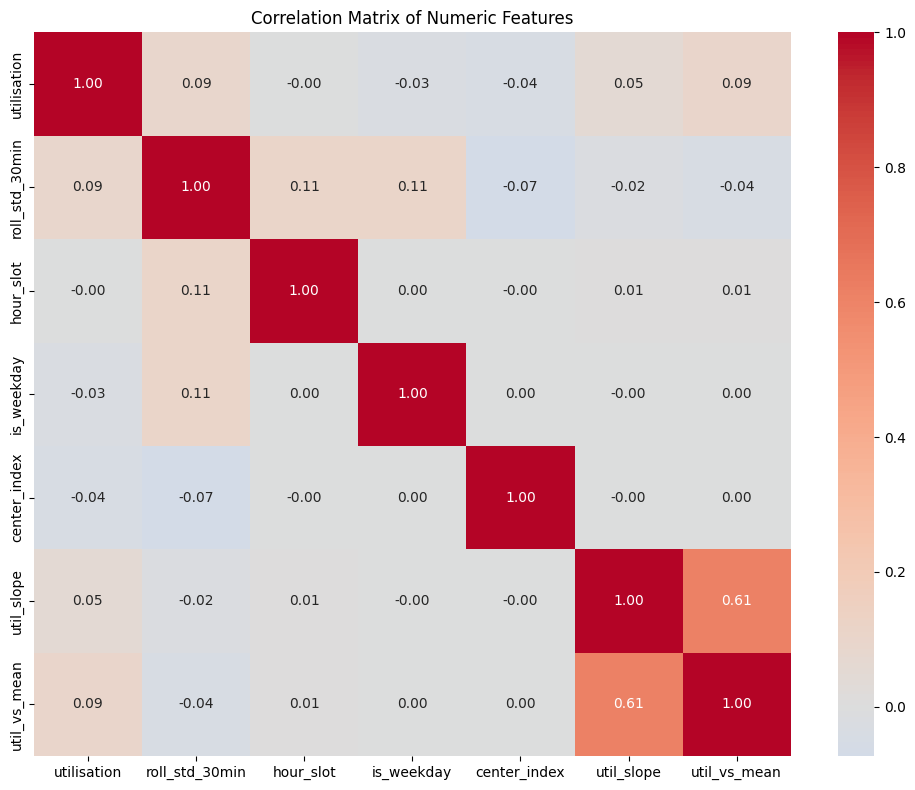

util_slope      util_vs_mean      0.610689
util_vs_mean    util_slope        0.610689
roll_std_30min  hour_slot         0.105328
hour_slot       roll_std_30min    0.105328
roll_std_30min  is_weekday        0.105008
is_weekday      roll_std_30min    0.105008
util_vs_mean    utilisation       0.094863
utilisation     util_vs_mean      0.094863
                roll_std_30min    0.091850
roll_std_30min  utilisation       0.091850
center_index    roll_std_30min    0.073025
roll_std_30min  center_index      0.073025
utilisation     util_slope        0.054021
util_slope      utilisation       0.054021
center_index    utilisation       0.039985
dtype: float64


In [ ]:
numeric_features = [
    "utilisation",
    # "roll_mean_30min", #remove due to high correlation with utilisation
    "roll_std_30min",
    # "dock_ratio", #remove due to high correlation with utilisation
    "hour_slot",
    "is_weekday",
    "center_index",
    "util_slope",
    "util_vs_mean",
]

corr = df[numeric_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()


corr_pairs = corr.abs().unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0]

print(corr_pairs.head(15))

### 6.2 VIF on sampled encoded feature matrix

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

# Use the encoded feature matrix already prepared for modelling
X_vif = X.copy()

# Remove missing values just in case
X_vif = X_vif.dropna().copy()

# Sample for speed
sample_size = min(50000, len(X_vif))
X_vif_sample = X_vif.sample(sample_size, random_state=42)

# Ensure numeric dtype
X_vif_sample = X_vif_sample.astype(float)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif_sample.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif_sample.values, i)
    for i in range(X_vif_sample.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)
vif_data.head(15)


# flag feature with high VIF
high_vif = vif_data[vif_data["VIF"] > 5].copy()
print("Features with VIF > 5:")
print(high_vif.to_string(index=False))

Features with VIF > 5:
     feature      VIF
center_index 5.192763


### VIF first run with all features:
`Features with VIF > 5:

feature:          VIF
-    utilisation:         inf
- roll_mean_30min:         inf
- util_vs_mean: 9.007199e+15
- center_index: 1.038968e+01
- dock_ratio: 8.105422e+00`

Variance Inflation Factor (VIF) analysis revealed perfect multicollinearity between utilisation, rolling mean, and deviation-from-mean features, due to a deterministic linear relationship. To resolve this, rolling mean was removed while retaining utilisation and deviation features, preserving interpretability and predictive information.
We also removed dock_ratio as complemenraty of utilisation.

### After removing dock_ratio and roll_mean_30min
Features with VIF > 5:
     feature      VIF
center_index 5.192763

which is acceptable.

## 7. Train/test split

In [ ]:

# Time‑based split: last 120 days as test
cutoff = df['last_reported'].max() - pd.Timedelta(days=120)
train_mask = df['last_reported'] < cutoff

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = df["band_30min"][train_mask], df["band_30min"][~train_mask]


## 8. Scaling

In [ ]:

# Scale features (except one‑hot)
scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("Train shape:", X_train_scaled.shape, "Test shape:", X_test_scaled.shape)

Train shape: (11085384, 9) Test shape: (2424434, 9)



## 9. Logistic model (empty stations)

In [ ]:
RANDOM_SEED = 42
y = df["empty_in_30min"]
y_train, y_test = df["empty_in_30min"][train_mask], df["empty_in_30min"][~train_mask]

model_empty = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
model_empty.fit(X_train_scaled, y_train)

y_pred = model_empty.predict(X_test_scaled)
y_proba = model_empty.predict_proba(X_test_scaled)[:, 1]

print(f'Classification Report:\n{classification_report(y_test, y_pred)}')
print(f"ROC AUC: {roc_auc_score(y_test, y_proba)}")

cm = confusion_matrix(y_test, y_pred)
print(f'Confusion Matrix:\n{cm}')


f1_macro = f1_score(y_test, y_pred, average="macro")
print(f"Macro F1: {f1_macro}")

roc_auc = roc_auc_score(y_test, y_proba)
print("ROC AUC:", roc_auc)

Classification Report:
              precision    recall  f1-score   support

       False       0.99      0.86      0.92   2069086
        True       0.54      0.96      0.69    355348

    accuracy                           0.88   2424434
   macro avg       0.77      0.91      0.81   2424434
weighted avg       0.93      0.88      0.89   2424434

ROC AUC: 0.9648948324539824
Confusion Matrix:
[[1784884  284202]
 [  15499  339849]]
Macro F1: 0.8082711223526406
ROC AUC: 0.9648948324539824


## 10. Logistic model (full stations)

In [ ]:
y = df["full_in_30min"]
y_train, y_test = df["full_in_30min"][train_mask], df["full_in_30min"][~train_mask]
model_full = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)
model_full.fit(X_train_scaled, y_train)



y_pred = model_full.predict(X_test_scaled)
y_proba = model_full.predict_proba(X_test_scaled)[:, 1]

print(f'Classification Report:\n{classification_report(y_test, y_pred)}')
print(f"ROC AUC: {roc_auc_score(y_test, y_proba)}")

cm = confusion_matrix(y_test, y_pred)
print(f'Confusion Matrix:\n{cm}')


f1_macro = f1_score(y_test, y_pred, average="macro")
print(f"Macro F1: {f1_macro}")

roc_auc = roc_auc_score(y_test, y_proba)
print("ROC AUC:", roc_auc)

Classification Report:
              precision    recall  f1-score   support

       False       1.00      0.91      0.95   2304345
        True       0.37      0.97      0.53    120089

    accuracy                           0.92   2424434
   macro avg       0.68      0.94      0.74   2424434
weighted avg       0.97      0.92      0.93   2424434

ROC AUC: 0.9802694495889708
Confusion Matrix:
[[2103661  200684]
 [   3560  116529]]
Macro F1: 0.7433239019337007
ROC AUC: 0.9802694495889708


## 11. Logistic model multimodal

In [ ]:
y = df["band_30min"]
y_train, y_test = df["band_30min"][train_mask], df["band_30min"][~train_mask]
print(y_train.value_counts(normalize=True).sort_index())


log_reg = LogisticRegression(
    max_iter=200,
    solver='saga',
    tol=1e-3,
    verbose=1
)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred, labels=band_labels))

band_30min
0    0.151699
1    0.307967
2    0.359706
3    0.129568
4    0.051060
Name: proportion, dtype: float64
Epoch 1, change: 1
Epoch 2, change: 0.25906255
Epoch 3, change: 0.14229336
Epoch 4, change: 0.10002043
Epoch 5, change: 0.078199169
Epoch 6, change: 0.06440155
Epoch 7, change: 0.054636785
Epoch 8, change: 0.047280827
Epoch 9, change: 0.041522395
Epoch 10, change: 0.036890616
Epoch 11, change: 0.033083629
Epoch 12, change: 0.02990259
Epoch 13, change: 0.027210542
Epoch 14, change: 0.024908181
Epoch 15, change: 0.022915261
Epoch 16, change: 0.021178897
Epoch 17, change: 0.01965319
Epoch 18, change: 0.018302819
Epoch 19, change: 0.017100516
Epoch 20, change: 0.016024967
Epoch 21, change: 0.015056369
Epoch 22, change: 0.014183079
Epoch 23, change: 0.013389596
Epoch 24, change: 0.012666402
Epoch 25, change: 0.012005652
Epoch 26, change: 0.011400726
Epoch 27, change: 0.010843805
Epoch 28, change: 0.010331266
Epoch 29, change: 0.0098569405
Epoch 30, change: 0.0094166307
Epoch 31,

band labels: [0, 1, 2, 3, 4]


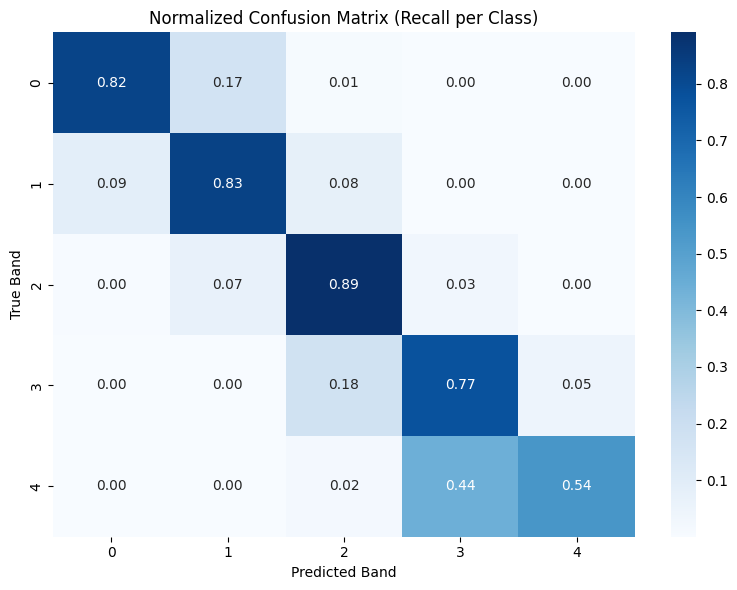

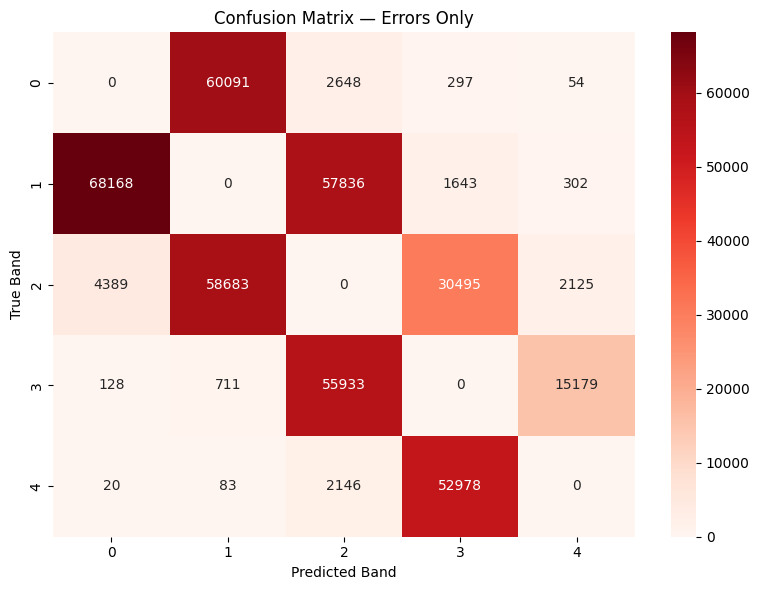

In [ ]:
#Confusion matrix for the logistic regression model
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

cm = confusion_matrix(y_test, y_pred, labels=band_labels)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
band_labels = [0, 1, 2, 3, 4]
print(f'band labels: {band_labels}')
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=band_labels,
    yticklabels=band_labels
)
plt.title("Normalized Confusion Matrix (Recall per Class)")
plt.ylabel("True Band")
plt.xlabel("Predicted Band")
plt.tight_layout()
plt.show()



# Confusion matrix for highlligh errors
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_errors, annot=True, fmt='d', cmap='Reds',
            xticklabels=band_labels,
            yticklabels=band_labels)
plt.title("Confusion Matrix — Errors Only")
plt.ylabel("True Band")
plt.xlabel("Predicted Band")
plt.tight_layout()
plt.show()